# TP — Comptage de mots et comparaison des méthodes

**Nom :** Alex Abdallah  
**Cours :** Fondements et Applications de Big Data

## Objectif

Comparer cinq méthodes de comptage des occurrences de mots :

1. Python séquentiel simple.
2. Pseudo-MapReduce en Python.
3. Hadoop MapReduce.
4. Apache Spark avec les RDD.
5. Apache Spark avec les DataFrames.

Les cinq méthodes sont testées sur les mêmes fichiers,
avec des tailles croissantes. Les comptes obtenus sont vérifiés
et les temps d'exécution sont comparés.

In [1]:
from pathlib import Path
import os
import random
import sys

TP = next((p for p in (Path.cwd(), Path.cwd() / "TP1") if (p / "compose.yaml").is_file()), None)
if TP is None:
    raise FileNotFoundError("Ouvrir le notebook depuis bigData/ ou bigData/TP1/.")
dossier = TP / "data"
dossier.mkdir(exist_ok=True)

N = 1_000
facteurs = [1, 10, 100, 1_000]

vocabulaire = [
    "chat", "chien", "arbre", "fleur", "maison",
    "soleil", "montagne", "livre", "ciel", "mer"
]

# Même fichier initial à chaque exécution.
generateur = random.Random(42)
lignes = [generateur.choice(vocabulaire) + "\n" for _ in range(N)]
bloc_initial = "".join(lignes)

fichiers = {}

for m in facteurs:
    chemin = dossier / f"mots_m{m}.txt"

    if not chemin.is_file():
        with chemin.open("w", encoding="utf-8", newline="\n") as fichier:
            for _ in range(m):
                fichier.write(bloc_initial)

    fichiers[m] = chemin

    print(
        f"{chemin.name} : {N * m:,} lignes, "
        f"{chemin.stat().st_size:,} octets"
    )

mots_m1.txt : 1,000 lignes, 7,117 octets
mots_m10.txt : 10,000 lignes, 71,170 octets
mots_m100.txt : 100,000 lignes, 711,700 octets
mots_m1000.txt : 1,000,000 lignes, 7,117,000 octets


## Méthode 1 — Python simple

Le programme lit le fichier et utilise un dictionnaire.
À chaque mot rencontré, son compteur augmente de 1.

In [2]:
def compter_python(chemin):
    with open(chemin, "r", encoding="utf-8") as fichier:
        mots = fichier.read().split()

    compteur = {}

    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1

    return compteur


resultat = compter_python(fichiers[1])
print(resultat)
print("Total :", sum(resultat.values()))

{'chien': 108, 'chat': 91, 'maison': 113, 'fleur': 116, 'arbre': 85, 'ciel': 103, 'mer': 95, 'montagne': 102, 'livre': 105, 'soleil': 82}
Total : 1000


## Méthode 2 — Pseudo-MapReduce Python

- Map : transforme chaque mot en une paire (mot, 1).
- Shuffle : regroupe les valeurs associées au même mot.
- Reduce : additionne ces valeurs.

Cette version s'exécute localement, sans parallélisation.

In [3]:
from collections import defaultdict


def mapper(ligne):
    return [(mot, 1) for mot in ligne.strip().split()]


def shuffle(paires):
    groupes = defaultdict(list)

    for mot, valeur in paires:
        groupes[mot].append(valeur)

    return groupes


def reducer(groupes):
    return {
        mot: sum(valeurs)
        for mot, valeurs in groupes.items()
    }


def compter_mapreduce(chemin):
    paires = []

    with open(chemin, "r", encoding="utf-8") as fichier:
        for ligne in fichier:
            paires.extend(mapper(ligne))

    return reducer(shuffle(paires))


resultat_mr = compter_mapreduce(fichiers[1])

assert resultat_mr == resultat
print("Les deux méthodes donnent les mêmes résultats.")

Les deux méthodes donnent les mêmes résultats.


In [4]:
from time import perf_counter
from statistics import median

mesures = []
reference = compter_python(fichiers[1])

methodes = {
    "Python simple": compter_python,
    "Pseudo-MapReduce": compter_mapreduce,
}

for m, chemin in fichiers.items():
    attendu = {
        mot: nombre * m
        for mot, nombre in reference.items()
    }

    for nom, fonction in methodes.items():
        durees = []

        for _ in range(3):
            debut = perf_counter()
            comptes = fonction(chemin)
            durees.append(perf_counter() - debut)

            assert comptes == attendu

        temps = median(durees)

        mesures.append({
            "m": m,
            "lignes": N * m,
            "octets": chemin.stat().st_size,
            "methode": nom,
            "temps_s": temps,
        })

        print(f"{N * m:>10,} lignes | {nom:<18} | {temps:.6f} s")

     1,000 lignes | Python simple      | 0.010020 s
     1,000 lignes | Pseudo-MapReduce   | 0.007702 s
    10,000 lignes | Python simple      | 0.010550 s


    10,000 lignes | Pseudo-MapReduce   | 0.016886 s


   100,000 lignes | Python simple      | 0.041963 s


   100,000 lignes | Pseudo-MapReduce   | 0.090403 s


 1,000,000 lignes | Python simple      | 0.408515 s


 1,000,000 lignes | Pseudo-MapReduce   | 1.017848 s


In [5]:
import pandas as pd
from IPython.display import Markdown, display

## Méthode 3 — Hadoop MapReduce

Hadoop est exécuté avec Docker Compose. Les fichiers de test
sont stockés dans HDFS et le programme WordCount fourni
avec Hadoop est exécuté avec YARN.

Map produit une paire (mot, 1) pour chaque occurrence.
Shuffle regroupe les valeurs par mot.
Reduce additionne les valeurs pour obtenir le nombre
d'occurrences de chaque mot.

Chaque fichier est testé et son temps d'exécution est mesuré.
Les résultats sont comparés à ceux de Python simple.

Le temps mesuré inclut le lancement de la commande Docker
et l'exécution du job Hadoop. Le transfert préalable dans
HDFS et la récupération du résultat sont exclus.

**Run All par défaut :** le notebook relit les résultats Hadoop déjà mesurés et vérifie les comptes mot par mot contre Python. Pour recalculer Hadoop avec HDFS et YARN, préparer Docker Compose comme indiqué dans le README et définir `TP1_HADOOP_LIVE=1` avant de lancer Jupyter.

In [6]:
if os.environ.get("TP1_HADOOP_LIVE") == "1":
    import subprocess
    import time
    from pathlib import Path

    dossier_tp = TP
    mesures_hadoop = []

    def executer_hadoop(*arguments):
        return subprocess.check_output(
            [
                "docker", "compose", "exec", "-T",
                "namenode", *arguments
            ],
            cwd=dossier_tp,
            text=True,
            encoding="utf-8",
            errors="replace"
        )

    print(executer_hadoop("hadoop", "version"))
    executer_hadoop("hdfs", "dfs", "-mkdir", "-p", "/tp/input")
    executer_hadoop("bash", "-lc", "hdfs dfs -put -f /data/mots_m*.txt /tp/input/")

    # Un nom différent à chaque lancement évite les dossiers
    # de sortie déjà existants dans HDFS.
    identifiant = time.time_ns()

    for m, chemin in fichiers.items():
        entree = f"/tp/input/mots_m{m}.txt"
        sortie = f"/tp/resultat_{identifiant}_m{m}"

        commande = (
            "hadoop jar "
            "/opt/hadoop/share/hadoop/mapreduce/"
            "hadoop-mapreduce-examples-*.jar "
            f"wordcount {entree} {sortie}"
        )

        debut = time.perf_counter()

        execution = subprocess.run(
            [
                "docker", "compose", "exec", "-T",
                "namenode", "bash", "-lc", commande
            ],
            cwd=dossier_tp,
            capture_output=True,
            text=True,
            encoding="utf-8",
            errors="replace"
        )

        duree = time.perf_counter() - debut

        if execution.returncode != 0:
            print(execution.stdout)
            print(execution.stderr)
            raise RuntimeError("Le job Hadoop a échoué.")

        texte = executer_hadoop(
            "hdfs", "dfs", "-cat", f"{sortie}/part-r-*"
        )

        comptes = {}
        for ligne in texte.splitlines():
            mot, nombre = ligne.split("\t")
            comptes[mot] = int(nombre)

        assert comptes == compter_python(chemin), (
            f"Résultats différents pour {chemin.name}"
        )

        mesures_hadoop.append({
            "m": m,
            "lignes": N * m,
            "methode": "Hadoop",
            "temps_s": duree
        })

        print(f"\nFichier : {chemin.name}")
        print(f"Nombre de lignes : {N * m:,}")
        print(f"Temps Hadoop : {duree:.6f} s")
        print("Résultats identiques à Python simple.")

        for mot, nombre in sorted(
            comptes.items(),
            key=lambda element: element[1],
            reverse=True
        ):
            print(f"{mot} : {nombre}")
    provenance_hadoop = "Hadoop recalculé (1 essai)"
else:
    mesures_hadoop = []
    archive = pd.read_csv(TP / "resultats" / "temps_hadoop.csv")
    for m, chemin in fichiers.items():
        sortie = TP / "resultats" / f"comptage_hadoop_m{m}.txt"
        comptes = {mot: int(n) for mot, n in (ligne.split("\t") for ligne in sortie.read_text().splitlines())}
        assert comptes == compter_python(chemin), f"Résultat Hadoop différent pour m={m}"
        essais = archive.loc[archive["m"].eq(m)]
        assert len(essais) == 3 and essais["correct"].all() and essais["temps_s"].gt(0).all()
        mesures_hadoop.append({"m": m, "lignes": N * m, "methode": "Hadoop",
                               "temps_s": essais["temps_s"].median()})
    provenance_hadoop = "Hadoop archivé (médiane de 3 essais)"
print(provenance_hadoop)

Hadoop archivé (médiane de 3 essais)


In [7]:
import pandas as pd

python_df = pd.DataFrame(mesures)
hadoop_df = pd.DataFrame(mesures_hadoop)

ensemble = pd.concat(
    [
        python_df[["lignes", "methode", "temps_s"]],
        hadoop_df[["lignes", "methode", "temps_s"]]
    ],
    ignore_index=True
)

comparaison = ensemble.pivot(
    index="lignes",
    columns="methode",
    values="temps_s"
).sort_index()

comparaison = comparaison[
    ["Python simple", "Pseudo-MapReduce", "Hadoop"]
]

comparaison.columns = [
    "Python simple (s)",
    "Pseudo-MapReduce (s)",
    "Hadoop (s)"
]

comparaison.index.name = "Nombre de lignes"

display(comparaison.round(6))

,Python simple (s),Pseudo-MapReduce (s),Hadoop (s)
Nombre de lignes,,,
1000,0.010020,0.007702,28.274664
10000,0.010550,0.016886,27.934216
100000,0.041963,0.090403,26.729210
1000000,0.408515,1.017848,29.596700


## Comparaison et analyse

Les comptes Hadoop sont identiques aux comptes des deux méthodes Python sur les quatre tailles. Le tableau indique les temps de cette session pour Python et la provenance affichée pour Hadoop.

Sur ces fichiers, la soumission du job, le lancement des tâches et la coordination sur HDFS et YARN pèsent dans le temps Hadoop. Les mesures d'une seule machine ne permettent pas de prédire les performances sur un cluster.

## Méthodes 4 et 5 — Apache Spark avec PySpark

Nous utilisons les mêmes fichiers que dans les méthodes précédentes.

PySpark est l'interface Python d'Apache Spark.
Le programme utilise les opérations suivantes :

- textFile : lire le fichier.
- flatMap : extraire les mots de chaque ligne.
- map : associer chaque mot à la valeur 1.
- reduceByKey : additionner les valeurs associées au même mot.
- collect : déclencher le calcul et récupérer les résultats.

Spark est exécuté directement dans le noyau, avec deux threads locaux. Le script original pour Docker reste disponible dans ce dossier.

### Deux façons d’exprimer le même calcul

- **RDD** : on décrit chaque transformation, puis on rassemble les comptes par mot avec `reduceByKey`.
- **DataFrame** : on décrit les colonnes à produire. `split` et `explode` créent une ligne par mot. `groupBy().count()` agrège les occurrences. Spark peut optimiser ce plan.

Les deux méthodes découpent les lignes sur les espaces. Elles sont mesurées dans la même session locale, après un premier calcul d’échauffement par API. On retient la médiane de trois mesures par fichier. Chaque calcul inclut la lecture et la collecte des comptes. Les caches de fichiers du système ne sont pas vidés entre essais.

In [8]:
from pyspark.sql import SparkSession, functions as F
from operator import add

os.environ["PYSPARK_PYTHON"] = sys.executable
spark = (SparkSession.builder.appName("ComptageMots")
         .master("local[2]")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.driver.host", "127.0.0.1")
         .config("spark.driver.bindAddress", "127.0.0.1")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/13 08:32:27 WARN Utils: Your hostname, LAPTOP-K2VAL7B9, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/13 08:32:27 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/13 08:32:29 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [9]:
def compter_rdd(chemin):
    return dict(spark.sparkContext.textFile(chemin.resolve().as_uri())
                .flatMap(lambda ligne: ligne.split())
                .map(lambda mot: (mot, 1))
                .reduceByKey(add)
                .collect())

def compter_dataframe(chemin):
    comptes = (spark.read.text(chemin.resolve().as_uri())
               .select(F.explode(F.split("value", r"\s+")).alias("mot"))
               .where(F.col("mot") != "")
               .groupBy("mot").count())
    return {ligne.mot: ligne["count"] for ligne in comptes.collect()}

methodes_spark = {"PySpark RDD": compter_rdd, "PySpark DataFrame": compter_dataframe}
mesures_spark = []
try:
    for fonction in methodes_spark.values():
        assert fonction(fichiers[1]) == reference
    for m, chemin in fichiers.items():
        attendu = {mot: nombre * m for mot, nombre in reference.items()}
        durees = {nom: [] for nom in methodes_spark}
        for repetition in range(3):
            ordre = list(methodes_spark)
            if repetition % 2:
                ordre.reverse()
            for nom in ordre:
                debut = perf_counter()
                comptes = methodes_spark[nom](chemin)
                durees[nom].append(perf_counter() - debut)
                assert comptes == attendu, f"Comptage incorrect pour {nom}, m={m}"
        for nom, essais in durees.items():
            temps = median(essais)
            mesures_spark.append({"lignes": N * m, "methode": nom, "temps_s": temps})
            print(f"{N * m:>10,} lignes | {nom:<17} | {temps:.6f} s | comptes vérifiés")
finally:
    spark.stop()

     1,000 lignes | PySpark RDD       | 0.450615 s | comptes vérifiés
     1,000 lignes | PySpark DataFrame | 0.447923 s | comptes vérifiés


    10,000 lignes | PySpark RDD       | 0.415587 s | comptes vérifiés
    10,000 lignes | PySpark DataFrame | 0.488598 s | comptes vérifiés


   100,000 lignes | PySpark RDD       | 0.584009 s | comptes vérifiés
   100,000 lignes | PySpark DataFrame | 0.545225 s | comptes vérifiés


 1,000,000 lignes | PySpark RDD       | 1.588506 s | comptes vérifiés
 1,000,000 lignes | PySpark DataFrame | 1.111626 s | comptes vérifiés


In [10]:
import pandas as pd

ensemble = pd.concat(
    [
        pd.DataFrame(mesures)[
            ["lignes", "methode", "temps_s"]
        ],
        pd.DataFrame(mesures_hadoop)[
            ["lignes", "methode", "temps_s"]
        ],
        pd.DataFrame(mesures_spark)[
            ["lignes", "methode", "temps_s"]
        ]
    ],
    ignore_index=True
)

comparaison_spark = ensemble.pivot(
    index="lignes",
    columns="methode",
    values="temps_s"
).sort_index()

comparaison_spark = comparaison_spark[
    ["Python simple", "Pseudo-MapReduce", "Hadoop", "PySpark RDD", "PySpark DataFrame"]
]

comparaison_spark.index.name = "Nombre de lignes"

display(comparaison_spark.round(6))

methode,Python simple,Pseudo-MapReduce,Hadoop,PySpark RDD,PySpark DataFrame
Nombre de lignes,,,,,
1000,0.010020,0.007702,28.274664,0.450615,0.447923
10000,0.010550,0.016886,27.934216,0.415587,0.488598
100000,0.041963,0.090403,26.729210,0.584009,0.545225
1000000,0.408515,1.017848,29.596700,1.588506,1.111626


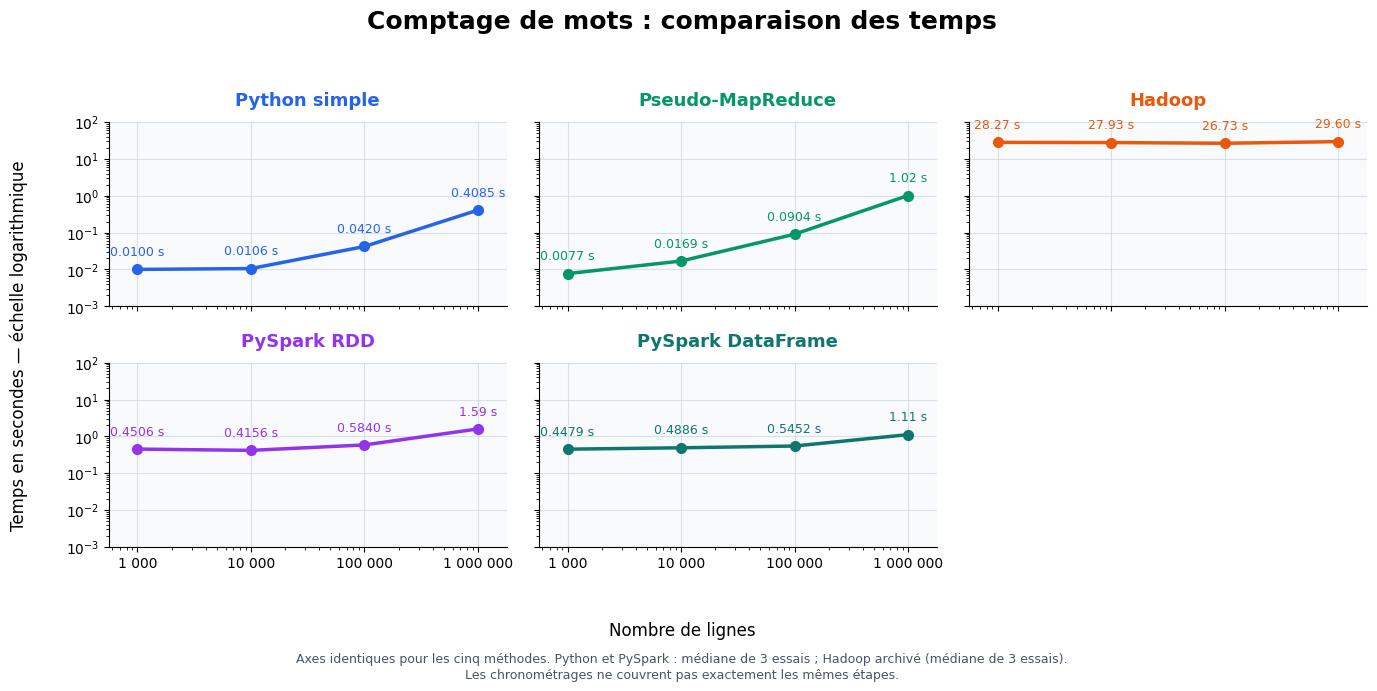

In [11]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np

methodes = [
    ("Python simple", "#2563EB"),
    ("Pseudo-MapReduce", "#059669"),
    ("Hadoop", "#EA580C"),
    ("PySpark RDD", "#9333EA"),
    ("PySpark DataFrame", "#0F766E"),
]

tailles = comparaison_spark.index.to_numpy()
valeurs = comparaison_spark[
    [nom for nom, couleur in methodes]
].to_numpy()

minimum = 10 ** np.floor(np.log10(valeurs.min()))
maximum = 10 ** np.ceil(np.log10(valeurs.max()))

with plt.rc_context({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
}):
    fig, axes = plt.subplots(
        2, 3,
        figsize=(14, 7),
        sharex=True,
        sharey=True
    )

    fig.suptitle(
        "Comptage de mots : comparaison des temps",
        fontsize=18,
        fontweight="bold",
        y=0.98
    )

    for ax, (methode, couleur) in zip(axes.flat, methodes):
        temps = comparaison_spark[methode].to_numpy()

        ax.set_facecolor("#F8FAFC")

        ax.plot(
            tailles,
            temps,
            color=couleur,
            linewidth=2.5,
            marker="o",
            markersize=7
        )

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_ylim(minimum, maximum)
        ax.set_xlim(tailles.min() / 1.8, tailles.max() * 1.8)

        ax.set_title(
            methode,
            color=couleur,
            fontsize=13,
            fontweight="bold",
            pad=12
        )

        ax.set_xticks(tailles)
        ax.xaxis.set_major_formatter(
            FuncFormatter(
                lambda valeur, position:
                f"{int(valeur):,}".replace(",", " ")
            )
        )

        ax.grid(
            True,
            which="major",
            color="#CBD5E1",
            alpha=0.7
        )

        for taille, duree in zip(tailles, temps):
            etiquette = (
                f"{duree:.2f} s"
                if duree >= 1
                else f"{duree:.4f} s"
            )

            ax.annotate(
                etiquette,
                (taille, duree),
                xytext=(0, 10),
                textcoords="offset points",
                ha="center",
                fontsize=9,
                color=couleur
            )

    axes.flat[-1].set_visible(False)
    fig.supxlabel("Nombre de lignes", y=0.08)
    fig.supylabel("Temps en secondes — échelle logarithmique")

    fig.text(
        0.5, 0.025,
        "Axes identiques pour les cinq méthodes. "
        f"Python et PySpark : médiane de 3 essais ; {provenance_hadoop}.\n"
        "Les chronométrages ne couvrent pas exactement les mêmes étapes.",
        ha="center",
        fontsize=9,
        color="#475569"
    )

    fig.tight_layout(rect=[0.025, 0.11, 1, 0.94])
    plt.show()

In [12]:
display(comparaison_spark.round(6))
for taille, durees in comparaison_spark.iterrows():
    methode = durees.idxmin()
    display(Markdown(f"**{taille:,} lignes :** {methode} a le temps le plus court ({durees[methode]:.4f} s)."))

methode,Python simple,Pseudo-MapReduce,Hadoop,PySpark RDD,PySpark DataFrame
Nombre de lignes,,,,,
1000,0.010020,0.007702,28.274664,0.450615,0.447923
10000,0.010550,0.016886,27.934216,0.415587,0.488598
100000,0.041963,0.090403,26.729210,0.584009,0.545225
1000000,0.408515,1.017848,29.596700,1.588506,1.111626


**1,000 lignes :** Pseudo-MapReduce a le temps le plus court (0.0077 s).

**10,000 lignes :** Python simple a le temps le plus court (0.0106 s).

**100,000 lignes :** Python simple a le temps le plus court (0.0420 s).

**1,000,000 lignes :** Python simple a le temps le plus court (0.4085 s).

## Conclusion — PySpark

Les cinq méthodes produisent les mêmes comptes. Les temps affichés au-dessus correspondent aux résultats de cette exécution, avec la provenance des mesures Hadoop indiquée sous le graphique.

Les calculs Python sont adaptés à ces fichiers de taille modeste. Hadoop lance un job et écrit les résultats intermédiaires des tâches Map sur le disque avant leur transfert aux tâches Reduce. Spark peut aussi écrire sur disque lors d'un shuffle. La lecture et la collecte sont mesurées pour chaque méthode Spark. Pour les volumes étudiés, les coûts de démarrage et de coordination influencent fortement les durées.

Le temps Spark exclut la création de la session, et le temps Hadoop inclut la soumission du job. Cette expérience compare des traitements locaux sur une seule machine ; elle ne permet pas de classer les moteurs sur un cluster ou sur des volumes plus importants.